# Лабораторная работа №2. Pandas и корреляционный анализ

В этой работе я разобрал два набора данных: пассажиров Titanic и таблицу brainsize.
Для Titanic посчитал пропуски и показатели по классам. Для brainsize сравнил
корреляции с `MRI_Count` отдельно у мужчин и женщин.

Решения находятся в `pandas_tasks.py` и `correlation_tasks.py`.
Ноутбук нужно запускать из папки лабораторной, рядом с файлами данных.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas_tasks import analyze_titanic
from correlation_tasks import analyze_brain_correlations
from grader_contracts.pandas_tasks import TitanicInput
from grader_contracts.correlation_tasks import BrainDataInput

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"


## 1. Titanic

Возраст оставил с пропусками. При подсчёте среднего Pandas пропускает `NaN`,
поэтому заменять его нулём не нужно. Долю выживших можно получить как среднее
столбца `Survived`, потому что в нём стоят 0 и 1.

In [2]:
titanic = pd.read_csv("titanic.csv")
result = analyze_titanic(TitanicInput("titanic.csv"))
print("Всего пассажиров:", result.row_count)
print("Старше 30 лет:", result.adults_over_30_count)
print("\nПропуски по столбцам:")
print(pd.Series(result.missing_by_column).to_string())
print("\nСредний возраст по классам:")
print(pd.Series(result.mean_age_by_pclass).round(2).to_string())
print("\nДоля выживших по классам, %:")
print((pd.Series(result.survival_rate_by_pclass) * 100).round(2).to_string())
print("\nПять самых больших тарифов:", result.highest_fares)


Всего пассажиров: 891
Старше 30 лет: 305

Пропуски по столбцам:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

Средний возраст по классам:
1    38.23
2    29.88
3    25.14

Доля выживших по классам, %:
1    62.96
2    47.28
3    24.24

Пять самых больших тарифов: [512.3292, 512.3292, 512.3292, 263.0, 263.0]


В таблице 891 пассажир, из них 305 старше 30 лет. Больше всего пропусков в
`Cabin` — 687. В `Age` не хватает 177 значений, а в `Embarked` — двух.

Средний возраст уменьшается от первого класса к третьему: 38,23; 29,88 и 25,14 года.
Доля выживших тоже выше в первом классе: 62,96% против 47,28% во втором и 24,24%
в третьем. По этим данным видно различие между классами, но одного такого
сравнения недостаточно, чтобы объяснить все причины выживания.

В списке тарифов есть повторы: задание просит пять наибольших значений,
а не пять разных тарифов.

## 2. Корреляционный анализ

Таблица разделена табуляцией, а пропуски обозначены `NA`. Разделил данные по полу,
чтобы посчитать коэффициенты отдельно. Корреляция считается по парам, где оба
значения известны: строки с пропуском веса не нужно удалять из остальных расчётов.

In [3]:
brain = pd.read_csv("brainsize.txt", sep="\t", na_values="NA")
result_brain = analyze_brain_correlations(BrainDataInput("brainsize.txt"))
features = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
print("Мужчин:", result_brain.men_count)
print("Женщин:", result_brain.women_count)
print("\nПропуски:")
print(brain.isna().sum().to_string())
correlations = pd.DataFrame({
    "Женщины": result_brain.women_mri_correlation,
    "Мужчины": result_brain.men_mri_correlation,
})
print("\nКорреляции с MRI_Count:")
print(correlations.round(3).to_string())
print("\nСамый связанный признак:", result_brain.strongest_mri_feature)


Мужчин: 20
Женщин: 20

Пропуски:
Gender       0
FSIQ         0
VIQ          0
PIQ          0
Weight       2
Height       1
MRI_Count    0

Корреляции с MRI_Count:
        Женщины  Мужчины
FSIQ      0.326    0.498
VIQ       0.255    0.413
PIQ       0.396    0.568
Weight    0.446   -0.077
Height    0.175    0.302

Самый связанный признак: PIQ


### Диаграммы рассеяния

Каждая точка — одно наблюдение. Сравнил все пять признаков с `MRI_Count`,
для каждой группы построил свой ряд графиков.

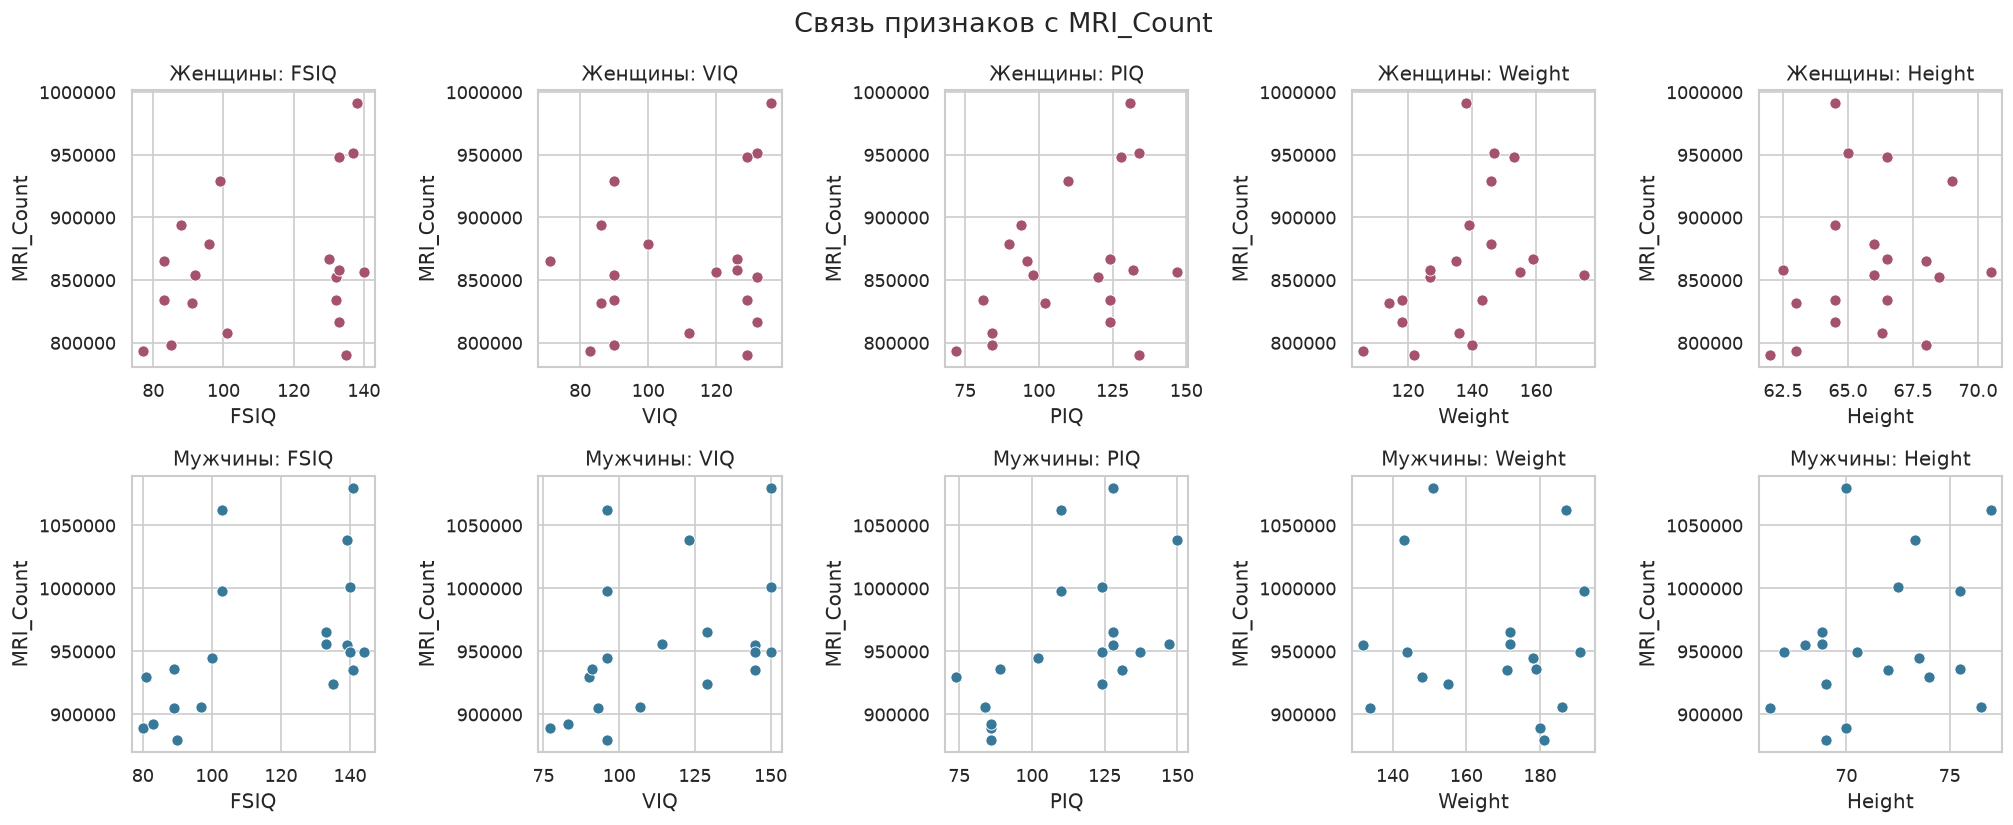

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for row, (gender, title) in enumerate([("Female", "Женщины"), ("Male", "Мужчины")]):
    group = brain[brain["Gender"] == gender]
    for col, feature in enumerate(features):
        ax = axes[row, col]
        sns.scatterplot(data=group, x=feature, y="MRI_Count", ax=ax,
                        color=["#a45270", "#38799a"][row], s=45)
        ax.set_title(f"{title}: {feature}")
        ax.ticklabel_format(axis="y", style="plain")
fig.suptitle("Связь признаков с MRI_Count", fontsize=16)
fig.tight_layout()
from pathlib import Path
Path("plots").mkdir(exist_ok=True)
fig.savefig("plots/scatter.png", dpi=150, bbox_inches="tight")
plt.show()


### Тепловые карты

На heatmap показал корреляции всех выбранных числовых признаков. Шкала одинакова
для двух групп: от −1 до 1, поэтому цвета можно сравнивать.

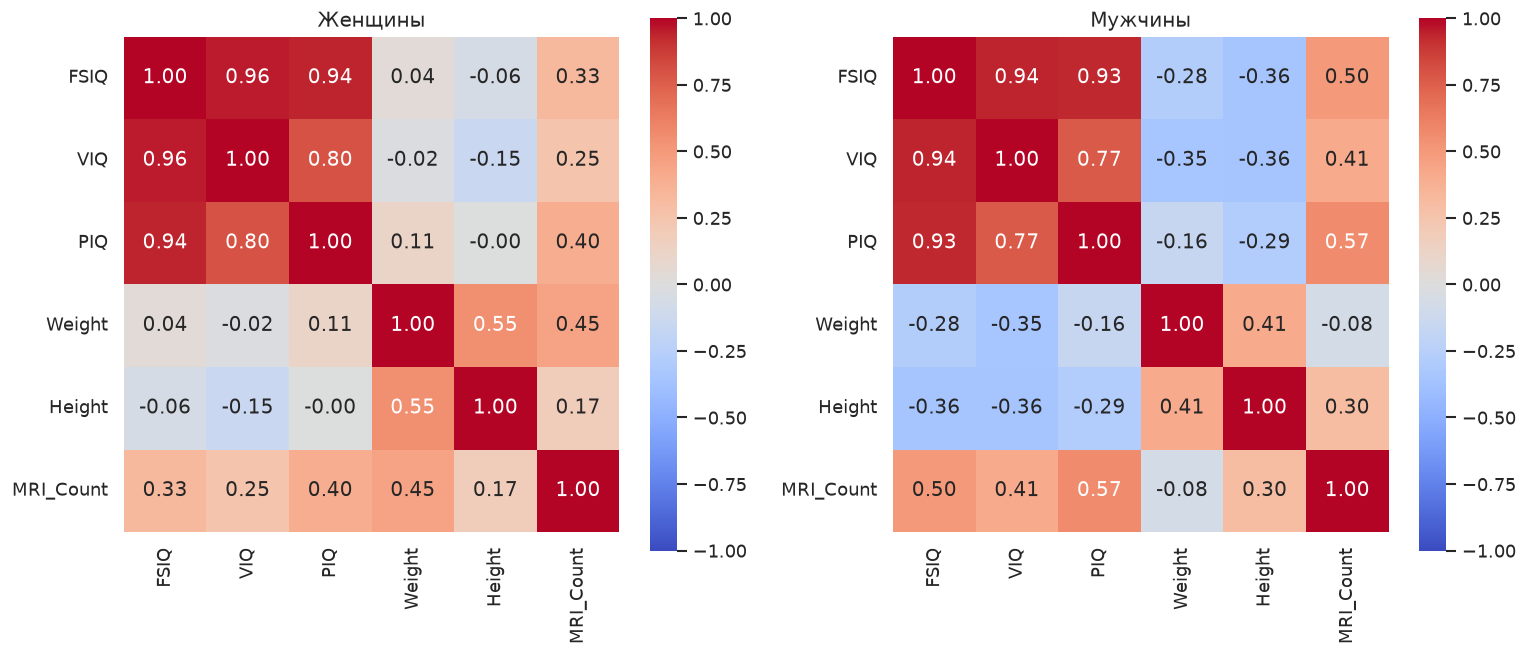

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
columns = features + ["MRI_Count"]
for ax, (gender, title) in zip(axes, [("Female", "Женщины"), ("Male", "Мужчины")]):
    group = brain[brain["Gender"] == gender]
    sns.heatmap(group[columns].corr(method="pearson"), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
    ax.set_title(title)
fig.tight_layout()
fig.savefig("plots/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Выводы

В каждой группе по 20 человек. Самая большая по модулю корреляция с `MRI_Count`
получилась у `PIQ` среди мужчин: примерно 0,568. Это умеренная положительная связь:
при большем `PIQ` значения `MRI_Count` в этой выборке в среднем выше.

У женщин сильнее всего связан с `MRI_Count` вес — примерно 0,446. У мужчин связь
веса с `MRI_Count` почти отсутствует: около −0,077. Значит, результаты двух групп
действительно отличаются, и раздельный расчёт здесь полезен.

На графиках точки заметно разбросаны. Выборка небольшая, поэтому делать широкие
выводы по ней я бы не стал. Также корреляция сама по себе не доказывает, что один
признак влияет на другой.

В итоге я потренировался читать таблицы, находить пропуски, использовать `groupby`
и считать корреляции. Важный момент — не подставлять нули вместо неизвестных
значений: это может изменить и средний возраст, и коэффициенты корреляции.